# Exercises from Lab 2

## 1. Probability Distribution Function (PDF) of Sentinel data

In [56]:
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

def analyze_sentinel_folder(folder_path, band_labels=('Blue', 'Green', 'Red', 'VH', 'VV')):
    folder = Path(folder_path)
    
    tif_files = sorted(list(folder.glob("*.tif")) + list(folder.glob("*.tiff")))
    
    if not tif_files:
        print(f"No TIFF files found in directory: {folder_path}")
        return

    num_files = len(tif_files)
    fig, axes = plt.subplots(1, num_files, figsize=(4 * num_files, 4), squeeze=False)
    axes = axes.flatten()

    for idx, file_path in enumerate(tif_files):
        label = band_labels[idx] if idx < len(band_labels) else f"Extra Band {idx+1}"
        
        with rasterio.open(file_path) as src:
            band_data = src.read(1)
            
            nodata_val = src.nodata
            if nodata_val is not None:
                valid_data = band_data[band_data != nodata_val].flatten()
            else:
                valid_data = band_data[band_data > 0].flatten()
            
            hist, bin_edges = np.histogram(valid_data, bins=256, density=True)
            bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
            
            axes[idx].plot(bin_centers, hist, color='tab:blue', lw=1.5)
            axes[idx].fill_between(bin_centers, hist, color='tab:blue', alpha=0.3)
            
            axes[idx].set_title(label, fontsize=11, fontweight='bold')
            axes[idx].set_xlabel("Pixel Intensity")
            axes[idx].set_ylabel("Density" if idx == 0 else "")
            axes[idx].grid(True, linestyle='--', alpha=0.6)

    plt.suptitle("Sentinel-2 & Sentinel-1 Band PDF Comparison", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

### Image 1 (Forest)

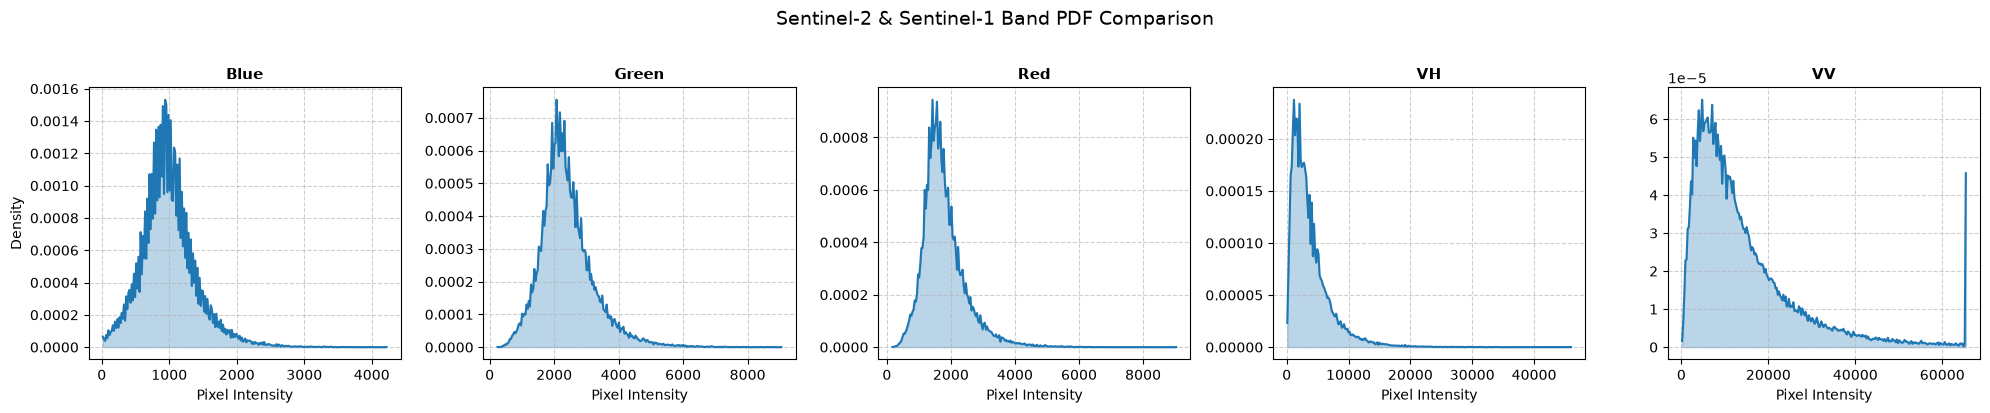

In [57]:
analyze_sentinel_folder("images/image-1")

### Image 2 (European City)

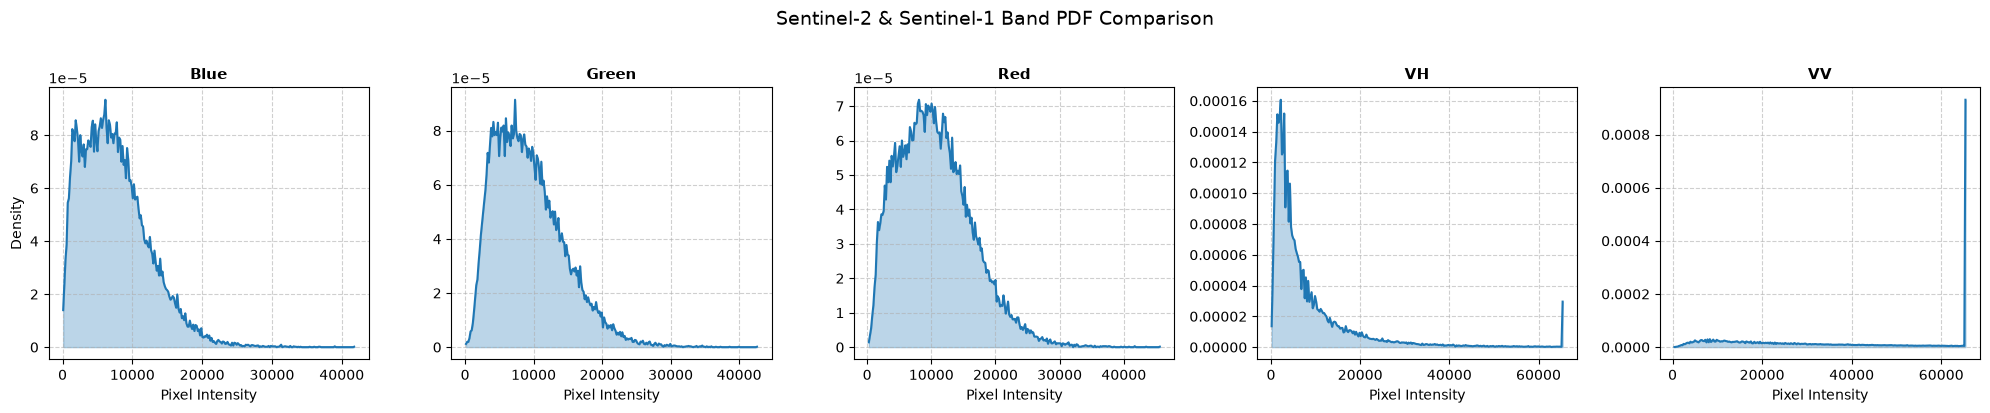

In [46]:
analyze_sentinel_folder("images/image-2")

### Image 3 (Hills)

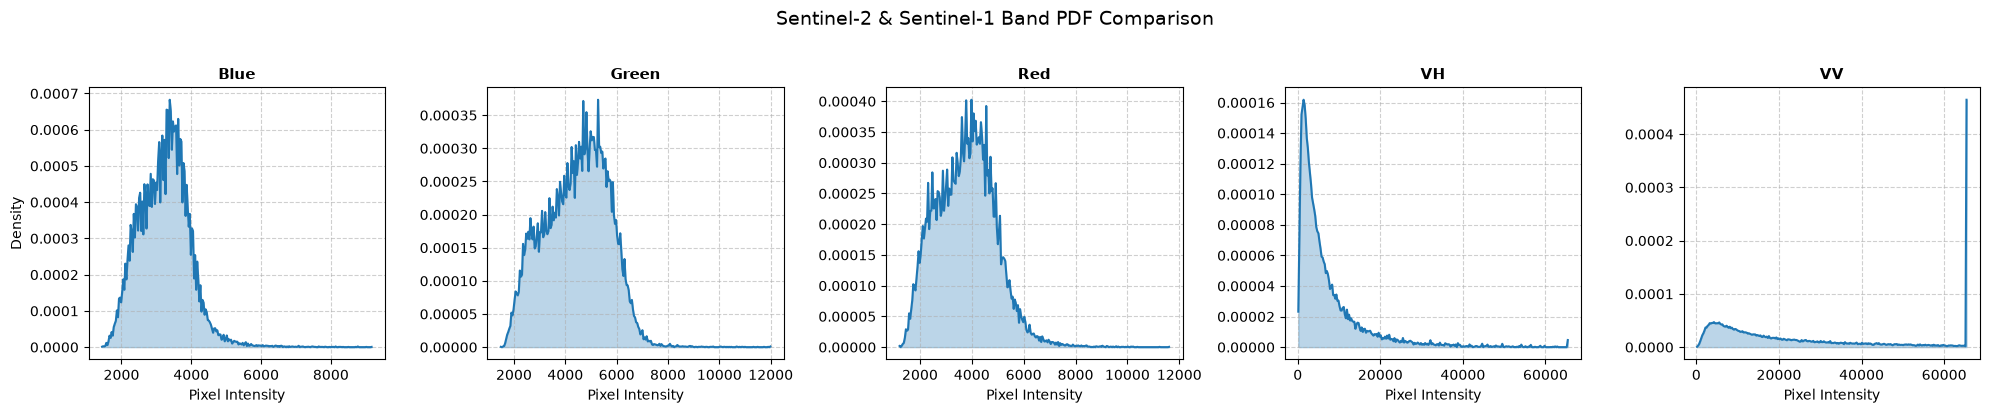

In [52]:
analyze_sentinel_folder("images/image-3")

### Image 4 (American City)

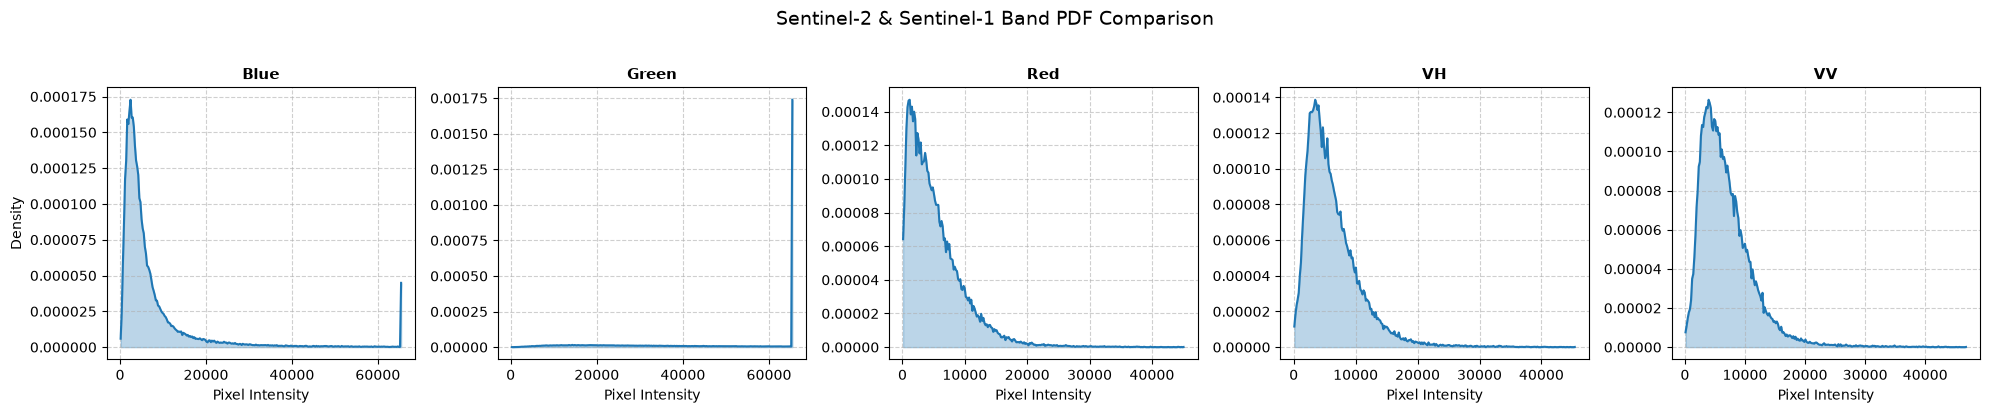

In [53]:
analyze_sentinel_folder("images/image-4")

Natural areas exhibit high densities of blue band pixels due to high reflactance of vegetation. Green and blue bands exhibit similiar peak pixel densities but for different intensities: green band has higher intensity of pixels on average than red band. The hill area additionally exhibited a second peak density of lower intensity pixels, possibly caused by the shading of the terrain by its shape. VH polarisation is greater than VV because vegetation reflects radio waves chaotically, scattering and increasing cross-polarisation.

Urban areas are more varied. The European city has broad spans of intensity of pixels due to a vast amount of surfaces with different colours and textures, reflecting light in unique ways. The American city has highly dense less intensive pixels due to the similar architecture used throughout, with a lack of green band pixels apart from maximum intensity ones (which are most probably an eror). The European ciy also has higher intensity of VH polarisation, which is due to the more varried surfaces of its buildings, while the American city has similar densities and intensities of its polarisations.

## 2. Stegenography

In [65]:
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

def batch_apply_lsb_steganography(input_folder, output_folder, band_labels=('Blue', 'Green', 'Red', 'VH', 'VV')):
    in_dir = Path(input_folder)
    out_dir = Path(output_folder)
    out_dir.mkdir(parents=True, exist_ok=True)
    
    tif_files = sorted(list(in_dir.glob("*.tif")) + list(in_dir.glob("*.tiff")))
    
    if not tif_files:
        print(f"No TIFF files found in directory: {input_folder}")
        return

    num_files = len(tif_files)
    fig, axes = plt.subplots(num_files, 2, figsize=(10, 3 * num_files), squeeze=False)

    for idx, file_path in enumerate(tif_files):
        label = band_labels[idx] if idx < len(band_labels) else f"Band {idx+1}"
        
        with rasterio.open(file_path) as src:
            profile = src.profile
            img_data = src.read(1)
            
            img_int = img_data.astype(np.uint16)
            
            max_val = np.iinfo(img_int.dtype).max
            mask = np.uint16(max_val ^ 3)
            cleared = img_int & mask
            
            random_bits = np.random.randint(0, 4, size=img_int.shape, dtype=np.uint16)
            
            manipulated = cleared | random_bits
            
            out_file_path = out_dir / f"manipulated_{file_path.name}"
            with rasterio.open(out_file_path, 'w', **profile) as dst:
                dst.write(manipulated.astype(profile['dtype']), 1)
                
            nodata_val = src.nodata
            if nodata_val is not None:
                valid_orig = img_int[img_int != nodata_val].flatten()
                valid_manip = manipulated[manipulated != nodata_val].flatten()
            else:
                valid_orig = img_int[img_int > 0].flatten()
                valid_manip = manipulated[manipulated > 0].flatten()
                
            hist_orig, bins = np.histogram(valid_orig, bins=256, density=True)
            hist_manip, _ = np.histogram(valid_manip, bins=256, range=(bins[0], bins[-1]), density=True)
            bin_centers = (bins[:-1] + bins[1:]) / 2
            
            axes[idx, 0].plot(bin_centers, hist_orig, color='tab:blue', lw=1.5)
            axes[idx, 0].fill_between(bin_centers, hist_orig, color='tab:blue', alpha=0.3)
            axes[idx, 0].set_title(f"{label} - Original", fontsize=10, fontweight='bold')
            axes[idx, 0].set_ylabel("Density")
            axes[idx, 0].grid(True, linestyle='--', alpha=0.5)
            
            axes[idx, 1].plot(bin_centers, hist_manip, color='tab:orange', lw=1.5, linestyle='--')
            axes[idx, 1].fill_between(bin_centers, hist_manip, color='tab:orange', alpha=0.3)
            axes[idx, 1].set_title(f"{label} - Manipulated (Random LSB)", fontsize=10, fontweight='bold')
            axes[idx, 1].grid(True, linestyle='--', alpha=0.5)

    plt.suptitle("PDF Comparison: Original vs. LSB-Manipulated Sentinel Bands", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

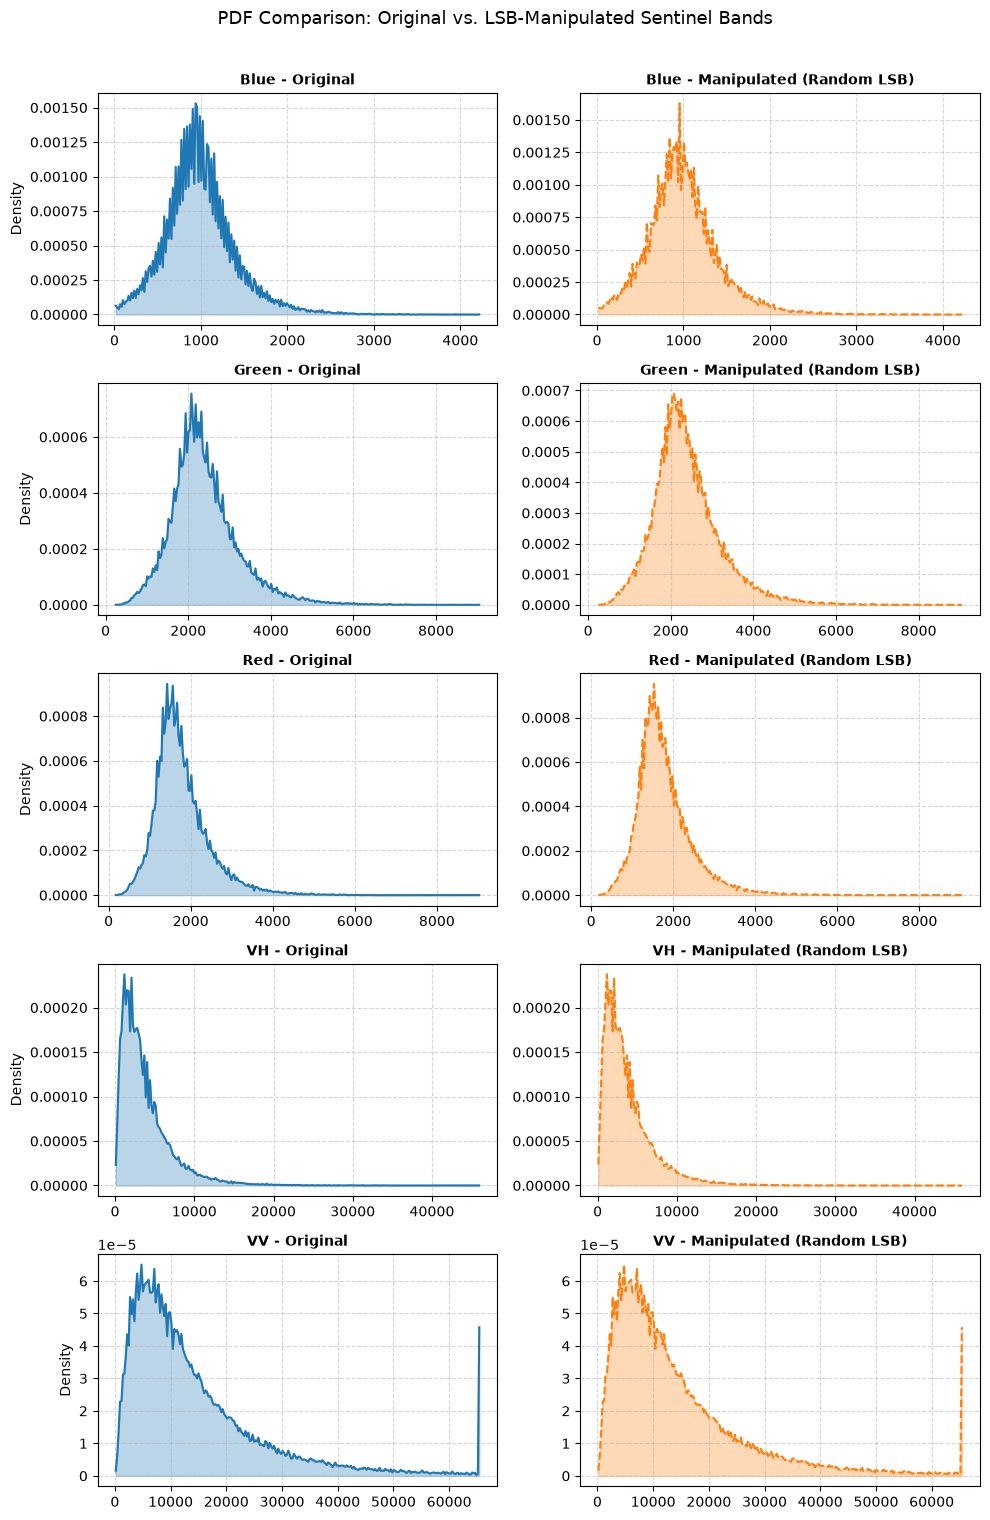

In [66]:
batch_apply_lsb_steganography("images/image-1", "images/image-1-changed")

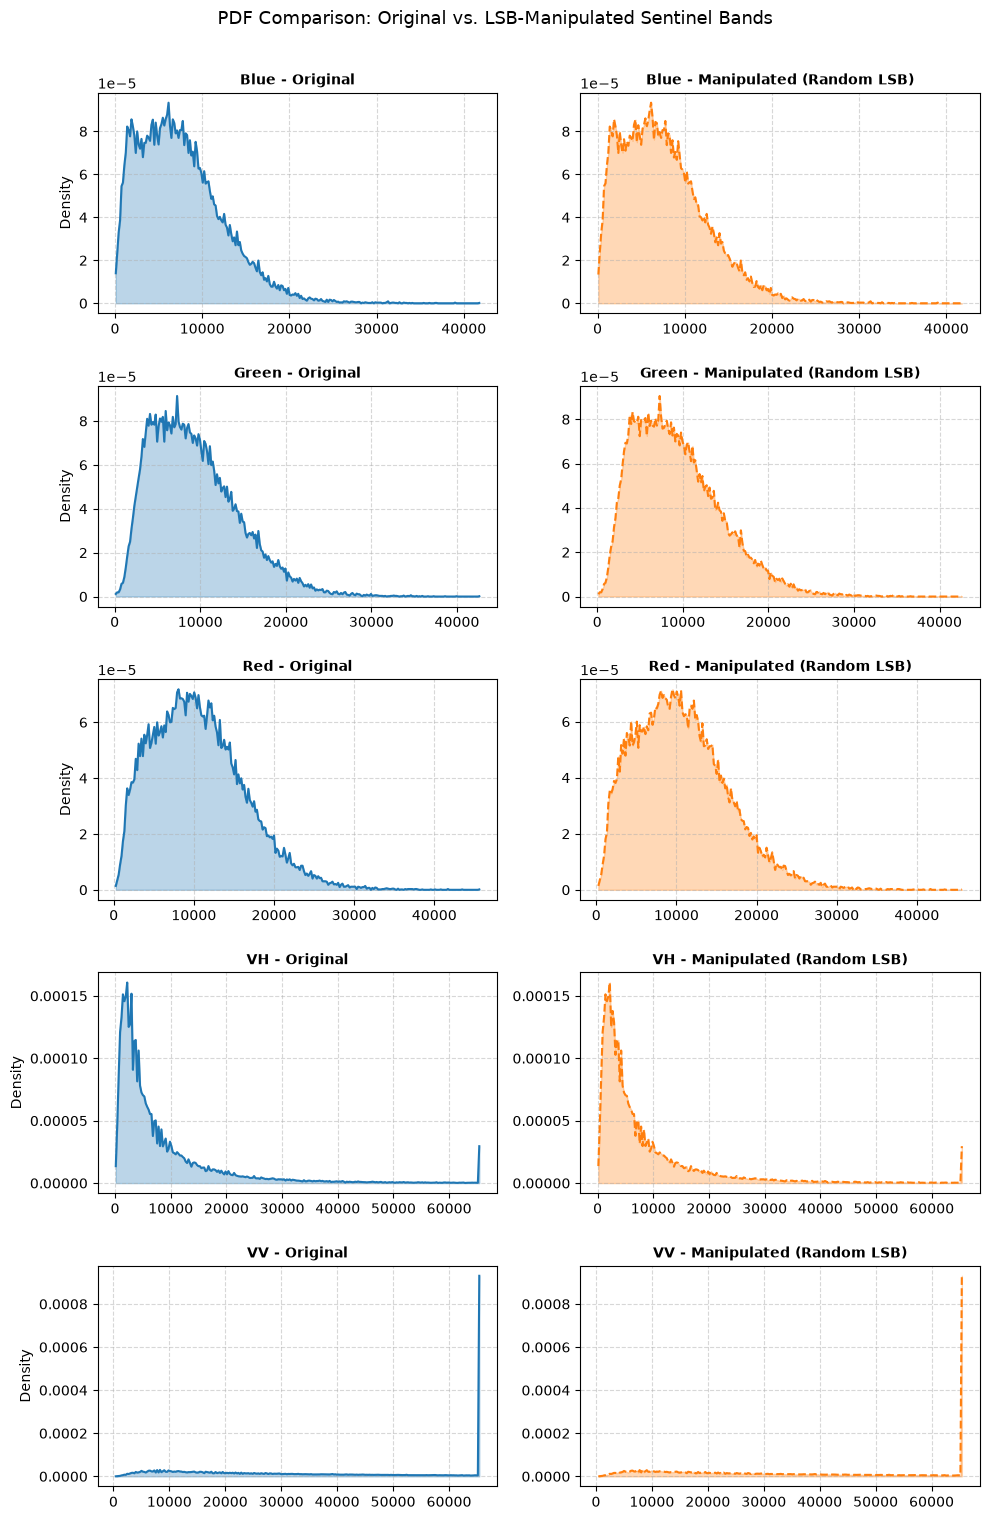

In [67]:
batch_apply_lsb_steganography("images/image-2", "images/image-2-changed")

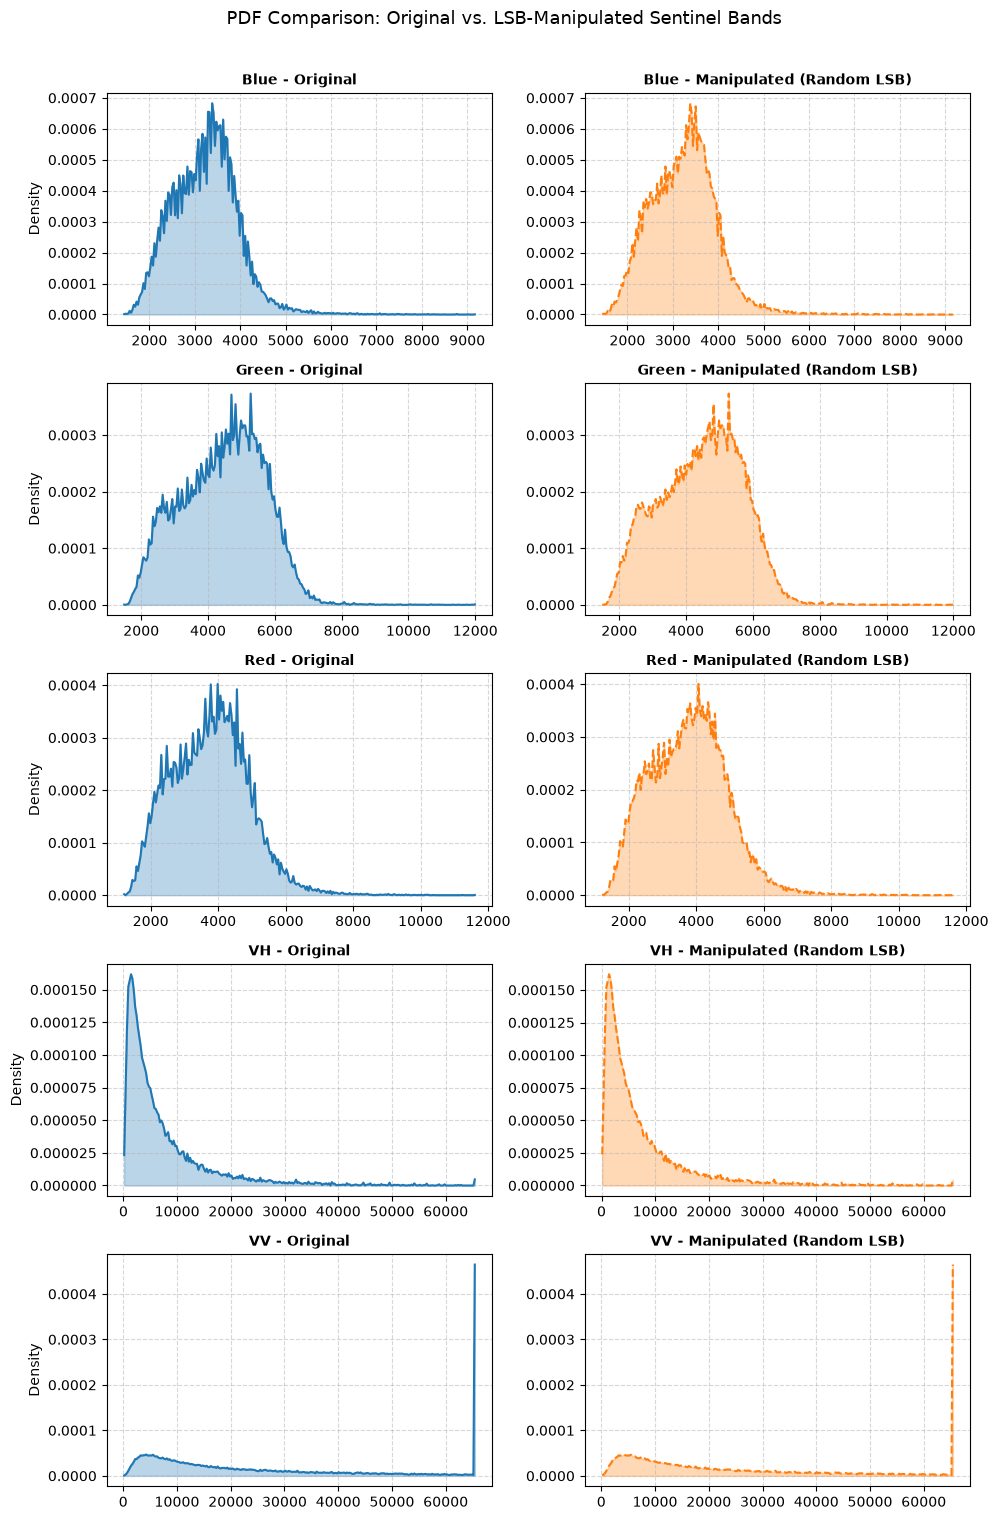

In [68]:
batch_apply_lsb_steganography("images/image-3", "images/image-3-changed")

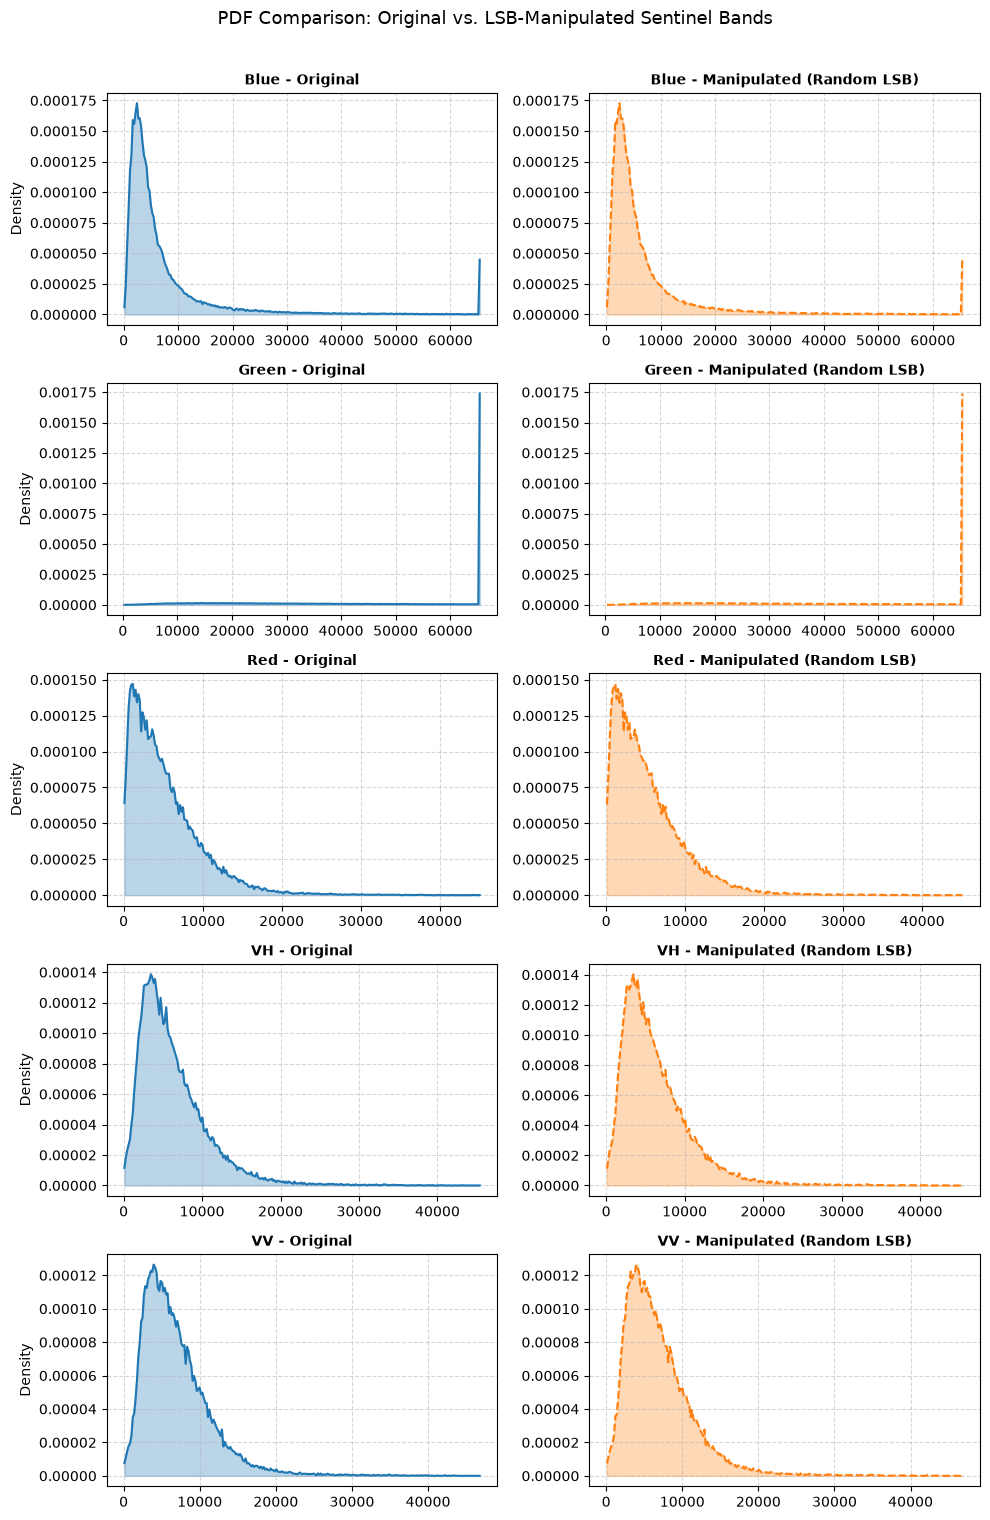

In [69]:
batch_apply_lsb_steganography("images/image-4", "images/image-4-changed")

The images themselves are visually unchanged, while the plots now have less noise, proiding smoother distributions. This is not enough to judge if images are manipulated, as it provides minimal evidence and does not provide any noticeable effect if the distributions originally have little noise.